In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Thiết lập giao diện hiển thị đồ thị cho đẹp
sns.set_theme(style="whitegrid")

# BƯỚC 1: KHỎANG KHỞI TẠO DỮ LIỆU MẪU
np.random.seed(42)  # Cố định số ngẫu nhiên để kết quả chạy luôn giống nhau

# Tạo DataFrame gồm 10 đơn hàng ngẫu nhiên thuộc 2 khu vực North và South
df_orders = pd.DataFrame(
    {
        "Order_ID": [f"ORD-{i:02d}" for i in range(1, 11)],
        "Region": np.random.choice(["North", "South"], 10),
        "Sales": np.random.randint(100, 500, 10),
    }
)

In [2]:
# BƯỚC 2: TÍNH TOÁN TỶ LỆ DỮ LIỆU (DÙNG TRANSFORM VÀ ASSIGN)

# 1. Dùng transform() để tính Tổng doanh số theo từng Khu vực
df_orders["Region_Total_Sales"] = df_orders.groupby("Region")["Sales"].transform(
    "sum"
)

# 2. Dùng assign() để tạo đồng thời các cột Tỷ lệ phần trăm mới
grand_total_sales = df_orders["Sales"].sum()

df_orders = df_orders.assign(
    # Tỷ lệ phần trăm đóng góp trên Tổng doanh số toàn cục (%)
    Pct_Grand_Total=lambda x: (x["Sales"] / grand_total_sales) * 100,
    # Tỷ lệ phần trăm đóng góp trong Nội bộ Khu vực (%)
    Pct_within_Region=lambda x: (x["Sales"] / x["Region_Total_Sales"]) * 100,
)

# In bảng dữ liệu sau khi tính toán ra màn hình
print("=" * 70)
print("BẢNG DỮ LIỆU CHI TIẾT SAU KHI TÍNH TOÁN:")
print("=" * 70)
print(
    df_orders[
        [
            "Order_ID",
            "Region",
            "Sales",
            "Region_Total_Sales",
            "Pct_Grand_Total",
            "Pct_within_Region",
        ]
    ].round(2)
)
print("\n")

BẢNG DỮ LIỆU CHI TIẾT SAU KHI TÍNH TOÁN:
  Order_ID Region  Sales  Region_Total_Sales  Pct_Grand_Total  \
0   ORD-01  North    314                1902             9.82   
1   ORD-02  South    430                1297            13.44   
2   ORD-03  North    187                1902             5.85   
3   ORD-04  North    472                1902            14.75   
4   ORD-05  North    199                1902             6.22   
5   ORD-06  South    459                1297            14.35   
6   ORD-07  North    251                1902             7.85   
7   ORD-08  North    230                1902             7.19   
8   ORD-09  North    249                1902             7.78   
9   ORD-10  South    408                1297            12.75   

   Pct_within_Region  
0              16.51  
1              33.15  
2               9.83  
3              24.82  
4              10.46  
5              35.39  
6              13.20  
7              12.09  
8              13.09  
9            

In [3]:
# BƯỚC 3: TRỰC QUAN HÓA DỮ LIỆU TÍNH TOÁN

# 1. Tổng hợp dữ liệu Tỷ lệ Toàn cục cho Biểu đồ Tròn (Pie Chart)
region_summary = (
    df_orders.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Pct_Grand_Total=("Pct_Grand_Total", "sum"),
    )
    .reset_index()
)

# 2. Pivot dữ liệu Tỷ lệ Nội bộ cho Biểu đồ Cột Chồng (100% Stacked Bar Chart)
pivot_within = df_orders.pivot(
    index="Region", columns="Order_ID", values="Pct_within_Region"
).fillna(0)

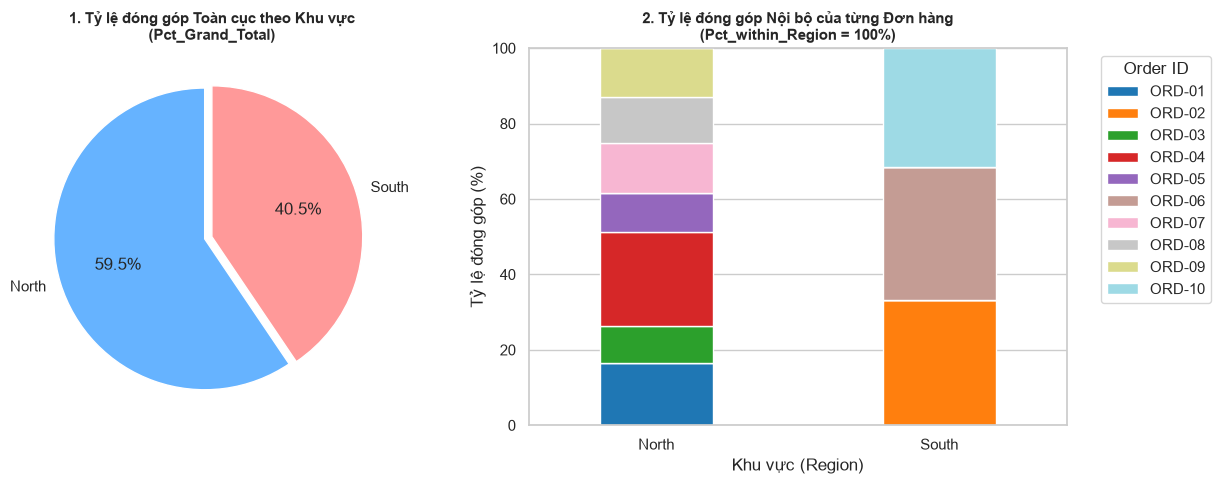

In [4]:
# 3. Khởi tạo khung vẽ chứa 2 biểu đồ song song (Subplots)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# [Biểu đồ 1] Pie Chart: Tỷ lệ đóng góp TOÀN CỤC (% Grand Total)
ax1.pie(
    region_summary["Pct_Grand_Total"],
    labels=region_summary["Region"],
    autopct="%1.1f%%",
    colors=["#66b3ff", "#ff9999"],
    startangle=90,
    explode=(0.05, 0),
)
ax1.set_title(
    "1. Tỷ lệ đóng góp Toàn cục theo Khu vực\n(Pct_Grand_Total)",
    fontsize=11,
    fontweight="bold",
)

# [Biểu đồ 2] Stacked Bar Chart: Tỷ lệ NỘI BỘ từng đơn hàng (% within Region)
pivot_within.plot(
    kind="bar", stacked=True, ax=ax2, colormap="tab20", width=0.4
)
ax2.set_title(
    "2. Tỷ lệ đóng góp Nội bộ của từng Đơn hàng\n(Pct_within_Region = 100%)",
    fontsize=11,
    fontweight="bold",
)
ax2.set_xlabel("Khu vực (Region)")
ax2.set_ylabel("Tỷ lệ đóng góp (%)")
ax2.legend(
    title="Order ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()